# SVI Model로 변동성 스마일 피팅하기

SVI 변동성 스마일 피팅을 수행하기 위한 기본 분석 환경을 구성하는 부분입니다.  
`numpy`와 `pandas`는 수치 계산과 데이터프레임 처리를 위해 사용되는 라이브러이며, `matplotlib`은 피팅 결과를 시각화하기 위한 용도입니다.  
`scipy.stats.norm`은 델타에서 행사가격을 역산할 때 필요한 표준정규분포의 역누적분포함수에 사용됩니다.  
`scipy.optimize.least_squares`는 SVI 모형의 파라미터를 시장 관측값에 맞추기 위한 비선형 최소자승법 기능입니다.  

 평가 기준일은 `2023-09-26`이며, 당시 USD/KRW 현물환율 `1352.93`로 설정합니다.  
이후 Colab의 `files.upload()`를 이용해 할인계수와 spot rate 열을 채운 로컬 CSV 파일을 직접 업로드하고, 업로드된 파일을 `pandas` 데이터프레임으로 읽어옵니다.  


In [2]:
import io
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm
from scipy.optimize import least_squares
from google.colab import files


# =========================================================
# 0) 로컬 CSV 파일 업로드 + 사용자 설정
# =========================================================
VALUATION_DATE = pd.Timestamp('2023-09-26') # 채워넣기
SPOT = 1352.93

# Commented out the files.upload() line as it's not needed if the file is already in Colab.
# uploaded = files.upload(/Users/iyong-gi/Documents/UFEA/과제/12주차_과제)   # 로컬에서 CSV 파일 선택
# file_name = next(iter(uploaded.keys()))

# Use the CSV file directly from the Colab environment
file_path = '/content/fx_option_vol_quotes_20230926_과제용_40기_김수린.csv'
raw = pd.read_csv(file_path)

print("Loaded file:", file_path)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())

Loaded file: /content/fx_option_vol_quotes_20230926_과제용_40기_김수린.csv
Shape: (24, 13)
Columns: ['Exp', 'ATM_bid', 'ATM_ask', 'RR25_bid', 'RR25_ask', 'BF25_bid', 'BF25_ask', 'RR10_bid', 'RR10_ask', 'BF10_bid', 'BF10_ask', 'df_usd', 'df_krw']


## 1. 만기 변환, 델타 기반 행사가격 산출, Raw SVI 함수 정의

이 단계에서는 SVI 피팅에 필요한 핵심 보조 함수들을 정의합니다.  
먼저 `tenor_to_maturity_date()` 함수는 `1D`, `1W`, `1M`, `1Y`와 같은 만기 표기를 실제 만기일로 변환합니다.  예를 들어 평가일이 2023년 9월 26일이고 만기가 `1W`라면, 만기일은 평가일로부터 1주 뒤의 날짜로 계산됩니다.    

`strike_from_forward_delta()` 함수는 FX 옵션시장에서 사용되는 forward delta 기준으로 특정 델타에 대응하는 행사가격을 역산하는 함수로 정의됩니다.  
Call 옵션의 forward delta는 N(d_1), Put 옵션의 forward delta는 N(-d_1)로 해석할 수 있으므로, 목표 델타에서 d_1값을 먼저 구한 뒤 행사가격 (K)를 계산합니다.  델타는 non-premium-adjusted forward delta를 기준으로 한다고 가정하겠습니다.

마지막으로 `raw_svi_total_variance()` 함수는 Raw SVI 모형의 총분산 함수를 정의합니다.  SVI는 내재변동성 자체가 아니라 총분산 w(k,T)를 log-moneyness (k=ln(K/F))의 함수이기 때문입니다.

In [3]:
# =========================================================
# 1) 기본 함수
# =========================================================
def tenor_to_maturity_date(start_date: pd.Timestamp, tenor: str) -> pd.Timestamp:
    tenor = str(tenor).strip().upper()
    m = re.fullmatch(r"(\d+)([DWMY])", tenor)
    if not m:
        raise ValueError(f"Unsupported tenor format: {tenor}")

    n = int(m.group(1))
    unit = m.group(2)

    if unit == "D":
        return start_date + pd.Timedelta(days=n)
    elif unit == "W":
        return start_date + pd.Timedelta(weeks=n)
    elif unit == "M":
        return start_date + pd.DateOffset(months=n)
    elif unit == "Y":
        return start_date + pd.DateOffset(years=n)
    else:
        raise ValueError(f"Unsupported tenor unit: {unit}")


def strike_from_forward_delta(target_delta, vol, T, F):
    """
    target_delta:
      call: +0.25, +0.10
      put : -0.25, -0.10
    forward delta (non-premium-adjusted) 기준
    """
    if T <= 0 or vol <= 0 or F <= 0:
        return np.nan

    if target_delta > 0:
        d1 = norm.ppf(target_delta)
    else:
        d1 = norm.ppf(target_delta + 1.0)

    K = F * np.exp(-d1 * vol * np.sqrt(T) + 0.5 * vol * vol * T)
    return K


def raw_svi_total_variance(k, a, b, rho, m, sigma):
    return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + sigma ** 2))

## 2. Raw FX Vol Quote를 SVI 입력 데이터로 변환

Bloomberg FX volatility quote 데이터를 SVI 모형에 입력할 수 있는 형태로 변환하는 전처리 과정입니다.  원본 데이터에는 당일 ATM volatility, risk reversal, butterfly quote가 bid/ask 형태로 나타나 있기에, 이를 mid quote로 변환해야 합니다.  각 quote의 mid 값은 bid와 ask의 단순 평균으로 계산하고, 백분율 단위로 입력된 변동성을 소수 단위로 변환합니다.  

FX 시장에서는 변동성 스마일이 직접 행사가격별 변동성으로 주어지기보다, ATM, RR, BF 조합으로 주어지기에  ATM, 25-delta call/put, 10-delta call/put에 해당하는 5개 smile point를 우선 복원합니다.  
예를 들어 25-delta call volatility는 `ATM + BF25 + 0.5 × RR25`로 계산되고, 25-delta put volatility는 `ATM + BF25 - 0.5 × RR25`로 계산됩니다.  

USD/KRW forward rate는 현물환율과 양 통화의 할인계수를 이용해 계산합니다.  
이 코드에서는 `forward = spot × df_usd / df_krw`를 사용하며, 이는 FX forward pricing에서 외화와 국내통화 할인계수의 상대적 차이를 반영하는 방식입니다.  
이후 각 smile point에 대해 델타에 대응하는 행사가격을 계산하고, 행사가격을 forward로 나눈 log-moneyness k=ln(K/F)를 산출합니다.  

최종적으로 각 만기별로 10P, 25P, ATM, 25C, 10C의 5개 관측점이 생성되며  이후 SVI 파라미터를 만기별로 추정하는 입력 데이터로 사용됩니다.

In [4]:
# =========================================================
# 2) 전처리: raw quote -> svi_input
# =========================================================
def build_svi_input(raw: pd.DataFrame,
                    valuation_date: pd.Timestamp = VALUATION_DATE,
                    spot: float = SPOT) -> pd.DataFrame:
    df = raw.copy()

    # tenor -> maturity -> T
    df["valuation_date"] = valuation_date
    df["maturity_date"] = df["Exp"].apply(lambda x: tenor_to_maturity_date(valuation_date, x))
    df["calendar_days"] = (df["maturity_date"] - df["valuation_date"]).dt.days
    df["T"] = df["calendar_days"] / 365.0

    # bid/ask -> mid (% -> decimal)
    quote_names = ["ATM", "RR25", "BF25", "RR10", "BF10"]
    for q in quote_names:
        df[f"{q}_mid_pct"] = (df[f"{q}_bid"] + df[f"{q}_ask"]) / 2.0
        df[f"{q}_mid"] = df[f"{q}_mid_pct"] / 100.0

    # RR/BF -> 5-point smile
    df["vol_atm"] = df["ATM_mid"]
    df["vol_25c"] = df["ATM_mid"] + df["BF25_mid"] + 0.5 * df["RR25_mid"]
    df["vol_25p"] = df["ATM_mid"] + df["BF25_mid"] - 0.5 * df["RR25_mid"]
    df["vol_10c"] = df["ATM_mid"] + df["BF10_mid"] + 0.5 * df["RR10_mid"]
    df["vol_10p"] = df["ATM_mid"] + df["BF10_mid"] - 0.5 * df["RR10_mid"]

    # forward
    df["forward"] = spot * df["df_usd"] / df["df_krw"]
    df["K_atm"] = df["forward"]

    records = []

    for _, row in df.iterrows():
        T = row["T"]
        F = row["forward"]

        point_specs = [
            ("10P", -0.10, row["vol_10p"]),
            ("25P", -0.25, row["vol_25p"]),
            ("ATM",  0.00, row["vol_atm"]),
            ("25C", +0.25, row["vol_25c"]),
            ("10C", +0.10, row["vol_10c"]),
        ]

        for label, target_delta, vol in point_specs:
            if label == "ATM":
                strike = row["K_atm"]
            else:
                strike = strike_from_forward_delta(
                    target_delta=target_delta,
                    vol=vol,
                    T=T,
                    F=F
                )

            records.append({
                "Exp": row["Exp"],
                "T": T,
                "forward": F,
                "point_label": label,
                "target_delta": target_delta,
                "implied_vol": vol,
                "implied_vol_pct": vol * 100.0,
                "strike": strike,
                "log_moneyness": np.log(strike / F) if pd.notna(strike) and strike > 0 and F > 0 else np.nan,
                "total_variance": vol * vol * T
            })

    svi_input = pd.DataFrame(records)

    label_order = {"10P": 0, "25P": 1, "ATM": 2, "25C": 3, "10C": 4}
    svi_input["label_order"] = svi_input["point_label"].map(label_order)

    return svi_input.sort_values(["Exp", "label_order"]).reset_index(drop=True)

## 3. 만기별 SVI Slice 피팅

SVI 모형은 총분산 (w(k,T))를 log-moneyness의 함수로 표현하며, 파라미터는 (a, b, \rho, m, sigma)의 5개입니다.  
각 만기마다 10P, 25P, ATM, 25C, 10C의 5개 시장 관측점을 이용해 해당 만기의 스마일을 추정합니다.  

`fit_svi_slice()` 함수는 하나의 만기 구간에 대해 SVI 파라미터를 추정합니다.  

`fit_all_svi_slices()` 함수는 전체 만기에 대해 이 피팅 과정을 반복합니다.  
또한 이전 만기의 추정 파라미터를 다음 만기의 초기값으로 사용하여 만기 간 파라미터가 지나치게 불연속적으로 변하지 않도록 유도하여 최종 결과로 각 만기별 SVI 파라미터, 총분산 RMSE, 변동성 RMSE, 최적화 성공 여부 등이 정리된 `svi_params` 데이터프레임이 생성됩니다.
이번에 이 데이터프레임을 사용하지는 않지만 모형의 타당성을 평가하고 싶다면 이 데이터프레임을 기초로 평가할 수 있습니다.

In [5]:
# =========================================================
# 3) SVI slice fitting
# =========================================================
def fit_svi_slice(slice_df, x0_override=None):
    slice_df = slice_df.dropna(subset=["log_moneyness", "total_variance", "implied_vol"]).copy()

    k = slice_df["log_moneyness"].values.astype(float)
    w = slice_df["total_variance"].values.astype(float)
    vol_obs = slice_df["implied_vol"].values.astype(float)
    T = float(slice_df["T"].iloc[0])

    # short tenor 여부
    short_tenor = T <= 7 / 365.0   # 1W 이하를 short tenor로 처리

    # 초기값
    if x0_override is None:
        x0 = np.array([
            max(1e-10, 0.8 * w.min()),
            max(1e-6, (w.max() - w.min()) / max(np.ptp(k), 1e-4)),
            0.0,
            float(k[np.argmin(w)]),
            0.05
        ])
    else:
        x0 = np.array(x0_override, dtype=float)

    # short tenor에서는 m을 너무 멀리 못 가게 조금 더 강하게 제한
    if short_tenor:
        lower = np.array([1e-12, 1e-10, -0.999, -0.05, 1e-6])
        upper = np.array([10.0, 100.0,  0.999,  0.05, 1.0])
    else:
        lower = np.array([1e-12, 1e-10, -0.999, -3.0, 1e-8])
        upper = np.array([10.0, 100.0,  0.999,  3.0, 2.0])

    def residuals(x):
        w_fit = raw_svi_total_variance(k, *x)
        vol_fit = np.sqrt(np.maximum(w_fit, 1e-16) / T)

        if short_tenor:
            # short tenor는 vol 기준 잔차를 우선시
            res_vol = (vol_fit - vol_obs) * 100.0
            # total variance 상대오차도 약하게 함께 반영
            res_w = 0.2 * (w_fit - w) / np.maximum(np.abs(w), 1e-10)
            return np.r_[res_vol, res_w]
        else:
            # 기존 방식 유지
            return w_fit - w

    res = least_squares(
        residuals,
        x0=x0,
        bounds=(lower, upper),
        max_nfev=30000
    )

    fitted_w = raw_svi_total_variance(k, *res.x)
    fitted_vol = np.sqrt(np.maximum(fitted_w, 0.0) / T)

    rmse_w = np.sqrt(np.mean((fitted_w - w) ** 2))
    rmse_vol = np.sqrt(np.mean((fitted_vol - vol_obs) ** 2)) * 100.0

    return {
        "a": res.x[0],
        "b": res.x[1],
        "rho": res.x[2],
        "m": res.x[3],
        "sigma": res.x[4],
        "rmse_total_variance": rmse_w,
        "rmse_vol_pctpt": rmse_vol,
        "success": res.success,
        "cost": res.cost,
        "n_points": len(slice_df)
    }


def fit_all_svi_slices(svi_input: pd.DataFrame, raw: pd.DataFrame) -> pd.DataFrame:
    params = []

    order_df = (
        svi_input.groupby("Exp", as_index=False)["T"]
        .first()
        .sort_values("T")
        .reset_index(drop=True)
    )

    prev_x0 = None

    for exp in order_df["Exp"]:
        s = svi_input[svi_input["Exp"] == exp].dropna(subset=["log_moneyness", "total_variance"])
        if len(s) < 5:
            continue

        result = fit_svi_slice(s.sort_values("log_moneyness"), x0_override=prev_x0)
        result["Exp"] = exp
        params.append(result)

        prev_x0 = np.array([
            result["a"], result["b"], result["rho"], result["m"], result["sigma"]
        ])

    svi_params = pd.DataFrame(params)

    exp_order = raw["Exp"].tolist()
    svi_params["Exp_order"] = svi_params["Exp"].apply(
        lambda x: exp_order.index(x) if x in exp_order else 9999
    )
    svi_params = svi_params.sort_values("Exp_order").drop(columns=["Exp_order"]).reset_index(drop=True)

    return svi_params

## 4. 시장 관측값과 SVI 피팅값 비교 및 개별 Smile 시각화

추정된 SVI 파라미터가 실제 시장 implied volatility를 얼마나 잘 설명하는지 확인합니다.  
`make_market_vs_fitted_table()` 함수는 특정 만기에 대해 시장 관측 IV와 SVI 모형이 계산한 fitted IV를 비교하는 표를 생성하는데요.  SVI 함수는 총분산을 출력하므로, 이를 다시 implied volatility로 다시 바꿔줍니다.

비교표에는 각 smile point의 만기, forward, strike, log-moneyness, 시장 IV, fitted IV, 오차가 포함됩니다. 이를 통해 특정 만기에서 SVI 모형이 ATM 근처를 잘 맞추는지, OTM call 또는 OTM put 영역에서 오차가 커지는지 확인할 수 있습니다.  

`plot_market_vs_fitted_slice_k()` 함수는 특정 만기의 smile을 2차원 그래프로 시각화합니다.  x축은 log-moneyness (k=ln(K/F)), y축은 내재변동성이며, 시장 관측점과 SVI 피팅 곡선을 함께 표시합니다.  이 그래프를 통해 단순히 숫자 오차만 보는 것이 아니라, smile의 기울기, 곡률, 좌우 비대칭성이 SVI 곡선에 의해 자연스럽게 표현되는지 시각적으로 점검할 수 있습니다.  

In [6]:
# =========================================================
# 4) fitted vs market 비교표 / plot
# =========================================================
def make_market_vs_fitted_table(exp: str,
                                svi_input: pd.DataFrame,
                                svi_params: pd.DataFrame) -> pd.DataFrame:
    slice_df = (
        svi_input[svi_input["Exp"] == exp]
        .dropna(subset=["strike", "log_moneyness", "total_variance", "implied_vol"])
        .copy()
        .sort_values("log_moneyness")
    )

    if len(slice_df) == 0:
        return None

    param_row = svi_params[svi_params["Exp"] == exp]
    if len(param_row) == 0:
        return None

    p = param_row.iloc[0]
    T = float(slice_df["T"].iloc[0])

    slice_df["observed_iv_pct"] = slice_df["implied_vol"] * 100.0
    slice_df["fitted_total_variance"] = raw_svi_total_variance(
        slice_df["log_moneyness"].values,
        p["a"], p["b"], p["rho"], p["m"], p["sigma"]
    )
    slice_df["fitted_iv_pct"] = np.sqrt(
        np.maximum(slice_df["fitted_total_variance"].values, 0.0) / T
    ) * 100.0

    slice_df["error_pctpt"] = slice_df["fitted_iv_pct"] - slice_df["observed_iv_pct"]
    slice_df["abs_error_pctpt"] = np.abs(slice_df["error_pctpt"])

    return slice_df.sort_values("label_order")[
        ["Exp", "point_label", "T", "forward", "strike", "log_moneyness",
         "observed_iv_pct", "fitted_iv_pct", "error_pctpt", "abs_error_pctpt"]
    ]


def plot_market_vs_fitted_slice_k(exp: str,
                                  svi_input: pd.DataFrame,
                                  svi_params: pd.DataFrame,
                                  grid_points: int = 400,
                                  pad_ratio: float = 0.20):
    comp = make_market_vs_fitted_table(exp, svi_input, svi_params)
    if comp is None:
        print(f"[SKIP] {exp}: usable point or fitted params not found.")
        return

    p = svi_params[svi_params["Exp"] == exp].iloc[0]
    T = float(comp["T"].iloc[0])

    k_obs = comp["log_moneyness"].values
    iv_obs = comp["observed_iv_pct"].values
    iv_fit_pts = comp["fitted_iv_pct"].values

    k_min = k_obs.min()
    k_max = k_obs.max()
    k_range = max(k_max - k_min, 1e-6)

    k_grid = np.linspace(
        k_min - pad_ratio * k_range,
        k_max + pad_ratio * k_range,
        grid_points
    )

    w_grid = raw_svi_total_variance(
        k_grid, p["a"], p["b"], p["rho"], p["m"], p["sigma"]
    )
    iv_grid = np.sqrt(np.maximum(w_grid, 0.0) / T) * 100.0

    plt.figure(figsize=(8, 5))
    plt.scatter(k_obs, iv_obs, s=65, label="Observed Market IV")
    plt.scatter(k_obs, iv_fit_pts, s=65, marker="x", label="Fitted IV at Market Points")
    plt.plot(k_grid, iv_grid, label="SVI Fitted Curve")

    for _, row in comp.iterrows():
        plt.annotate(
            row["point_label"],
            (row["log_moneyness"], row["observed_iv_pct"]),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=9
        )

    plt.xlabel("Log-Moneyness  k = ln(K / F)")
    plt.ylabel("Implied Volatility (%)")
    plt.title(f"Market vs Fitted SVI Smile - {exp}")
    plt.grid(True)
    plt.legend()
    plt.show()

## 5. 전체 만기별 SVI Smile 순차 출력

이 단계는 모든 만기에 대해 시장 IV와 SVI 피팅 결과를 순차적으로 확인하기 위한 과정입니다.  
`plot_all_tenor_smiles()` 함수는 `svi_params`에 포함된 각 만기를 하나씩 불러와 개별 smile 그래프를 출력합니다. 필요한 경우 `print_table=True`로 설정하면 각 만기별 시장 IV와 fitted IV의 비교표도 함께 확인할 수 있습니다.

마지막 실행 부분에서는 원본 데이터를 `build_svi_input()` 함수에 넣어 SVI 입력 데이터로 변환하고, `fit_all_svi_slices()`를 통해 전체 만기별 SVI 파라미터를 추정하며
이후 추정된 파라미터 테이블을 출력하고, 모든 만기별 smile 그래프를 순서대로 시각화합니다.  

[SVI Parameters]
               a         b       rho         m     sigma  rmse_total_variance  \
0   2.083183e-05  0.001009  0.096608  0.000341  0.005773         5.892209e-17   
1   1.298106e-04  0.001998  0.256447 -0.001489  0.010144         5.982792e-19   
2   2.525747e-04  0.003077  0.329962 -0.001013  0.014661         5.746852e-07   
3   3.787993e-04  0.003063  0.442328 -0.003515  0.014995         5.149275e-07   
4   5.506376e-04  0.004972  0.366472 -0.002072  0.021065         6.706037e-07   
5   1.083038e-03  0.007769  0.423692 -0.001472  0.029712         1.346245e-06   
6   1.319181e-03  0.012395  0.336614 -0.004385  0.048881         1.918165e-06   
7   1.749899e-03  0.014951  0.378787 -0.004102  0.059145         3.174766e-06   
8   1.945367e-03  0.019093  0.380164 -0.003494  0.073195         7.005224e-06   
9   1.270144e-03  0.026230  0.308691 -0.005140  0.102968         9.349415e-06   
10  8.720293e-04  0.038066  0.293391 -0.007461  0.137111         2.687332e-05   
11  1.00000

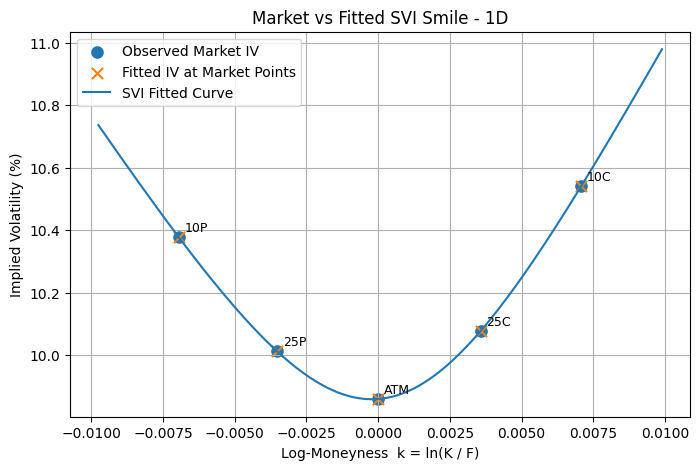

[Tenor: 1W]


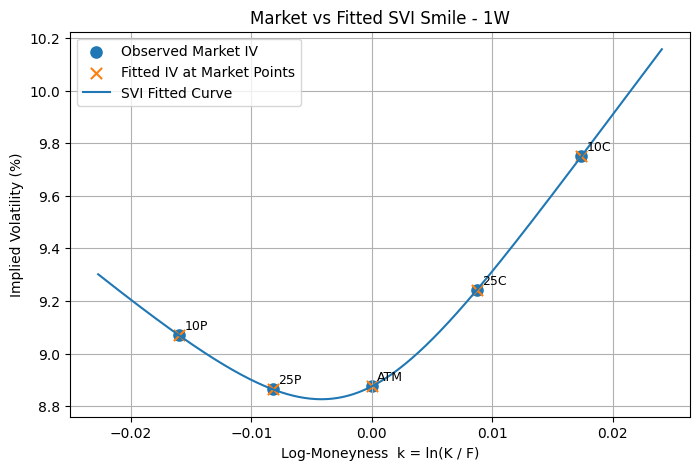

[Tenor: 2W]


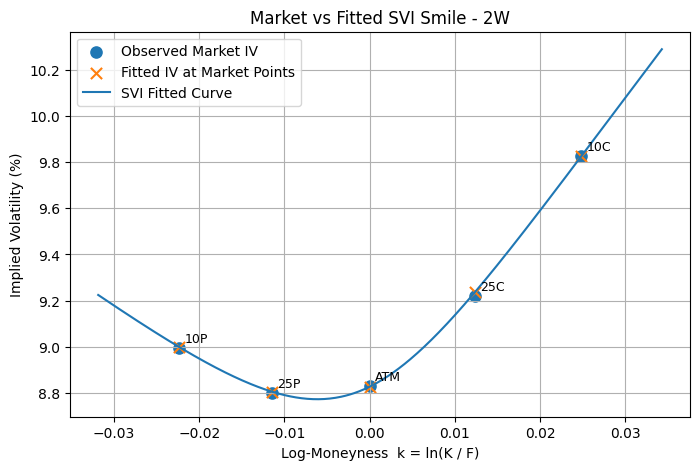

[Tenor: 3W]


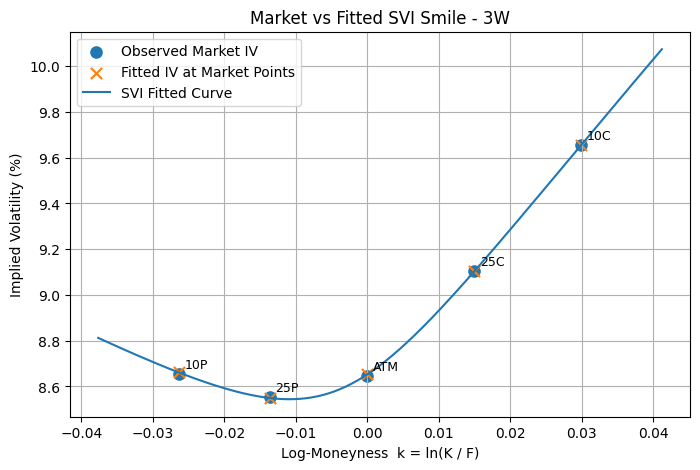

[Tenor: 1M]


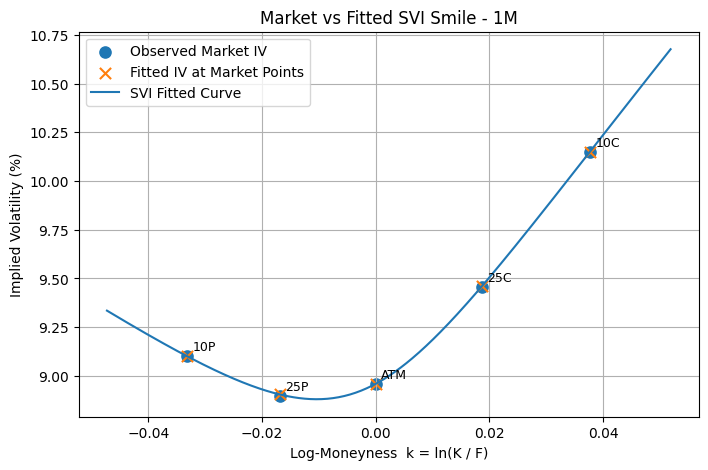

[Tenor: 2M]


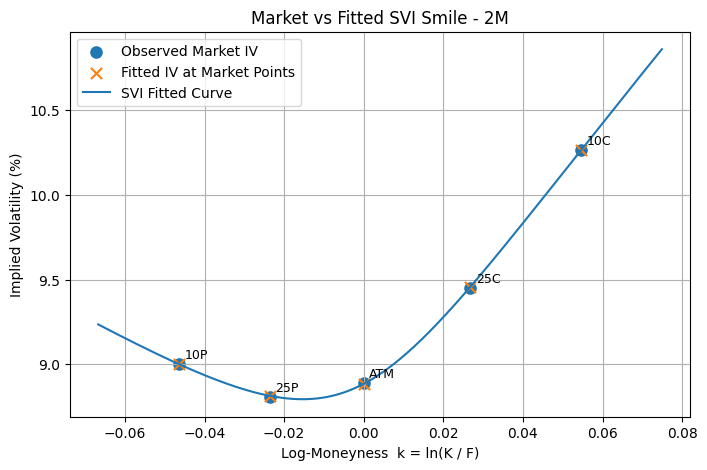

[Tenor: 3M]


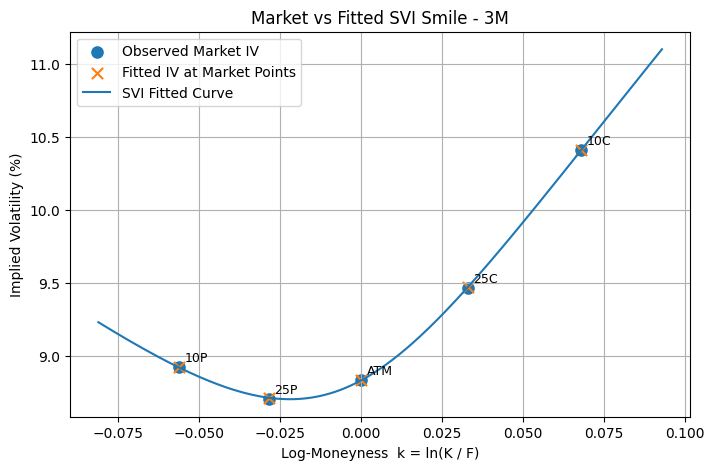

[Tenor: 4M]


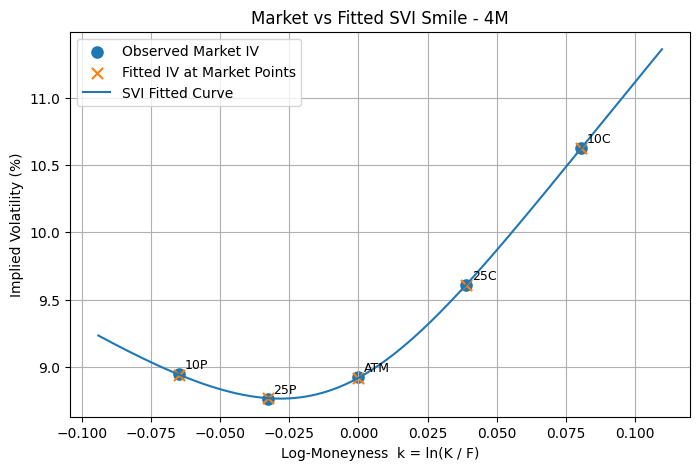

[Tenor: 5M]


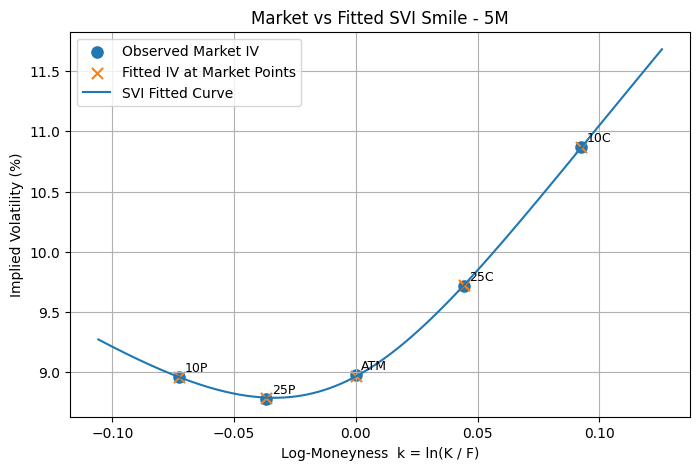

[Tenor: 6M]


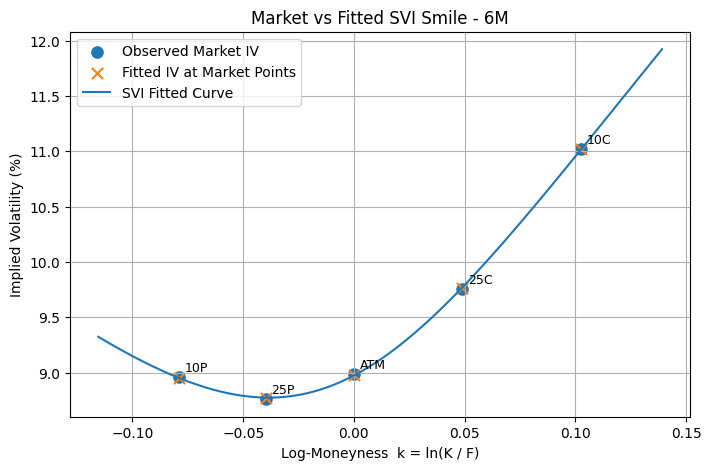

[Tenor: 9M]


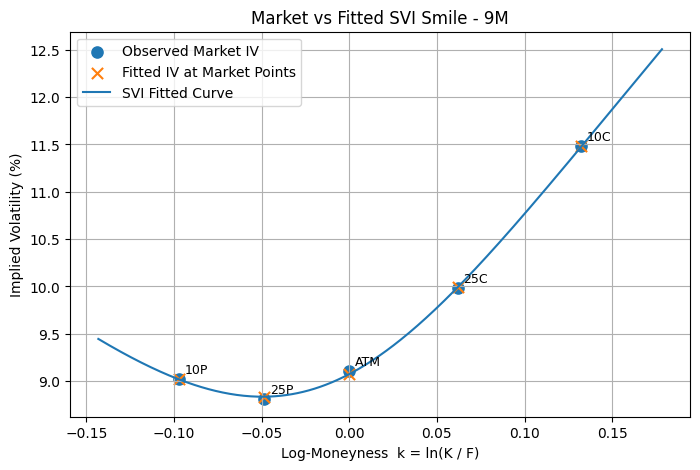

[Tenor: 1Y]


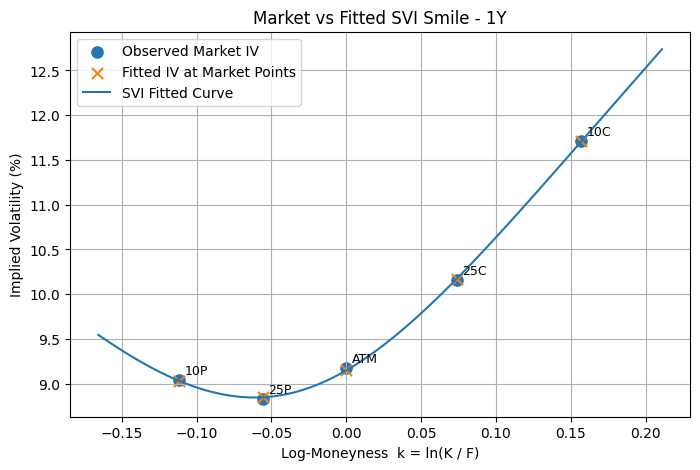

[Tenor: 18M]


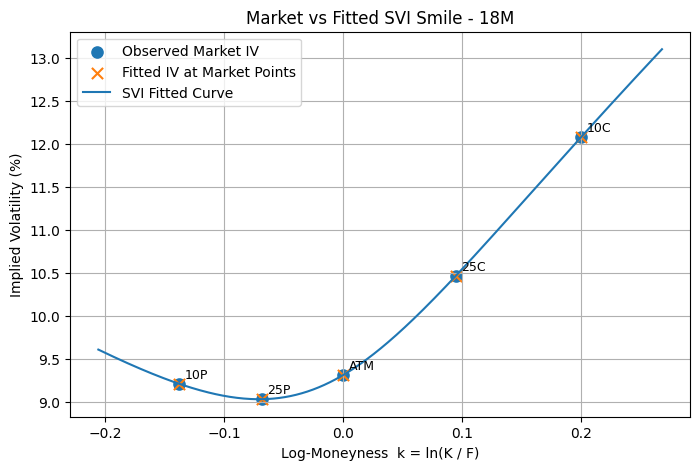

[Tenor: 2Y]


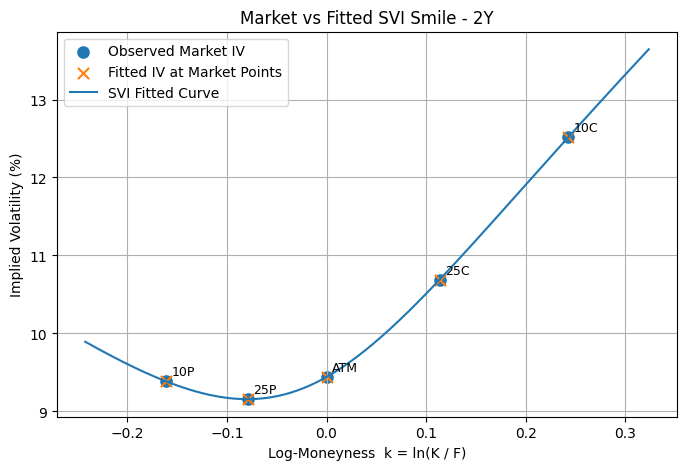

[Tenor: 3Y]


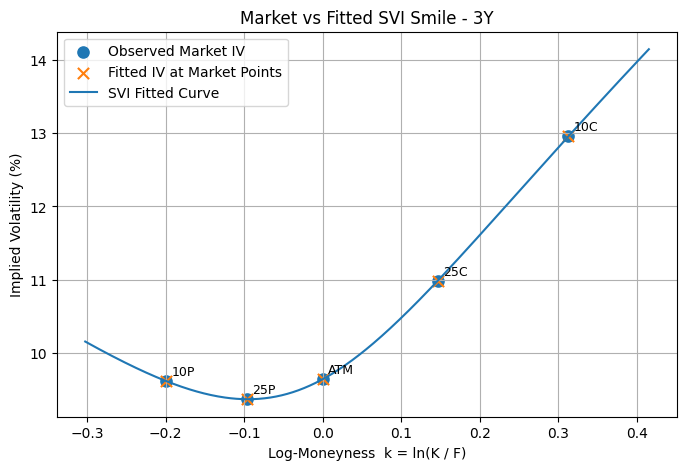

[Tenor: 4Y]


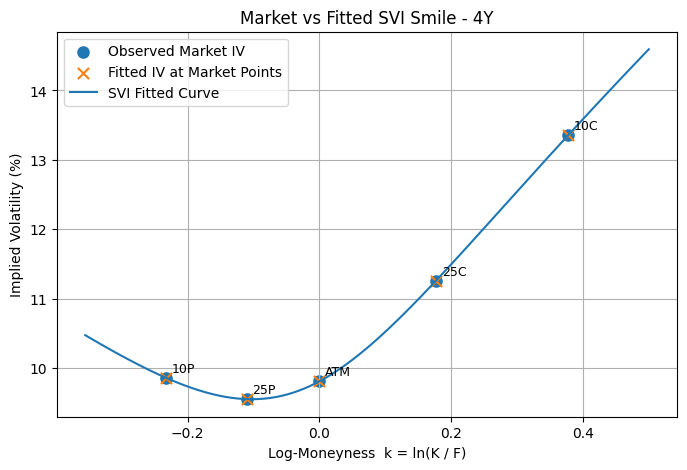

[Tenor: 5Y]


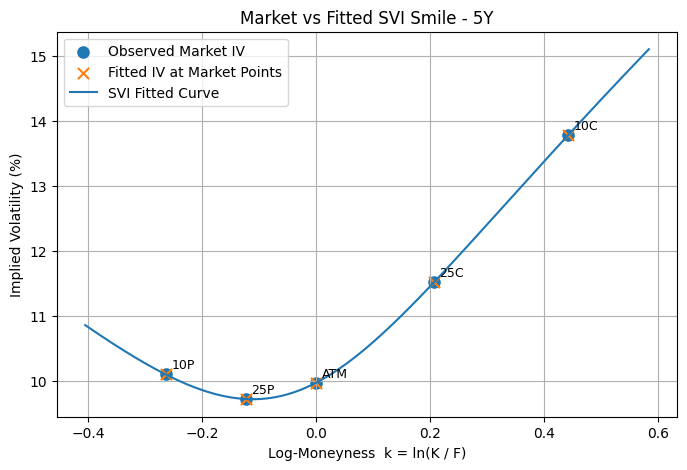

[Tenor: 6Y]


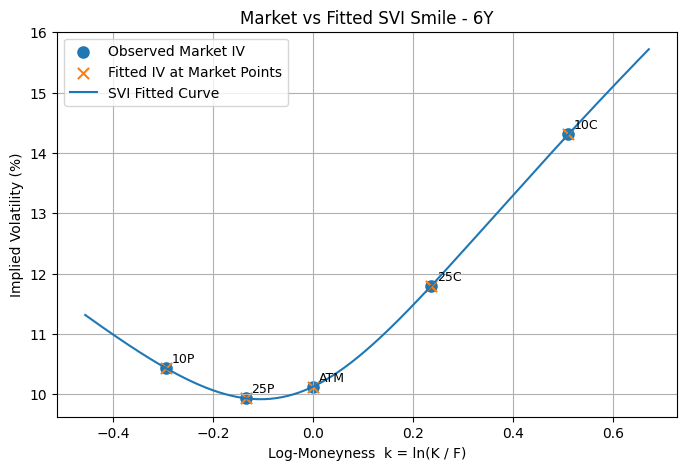

[Tenor: 7Y]


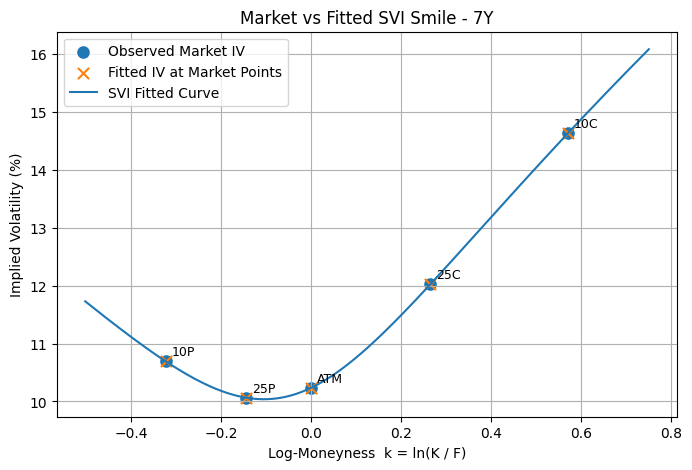

[Tenor: 10Y]


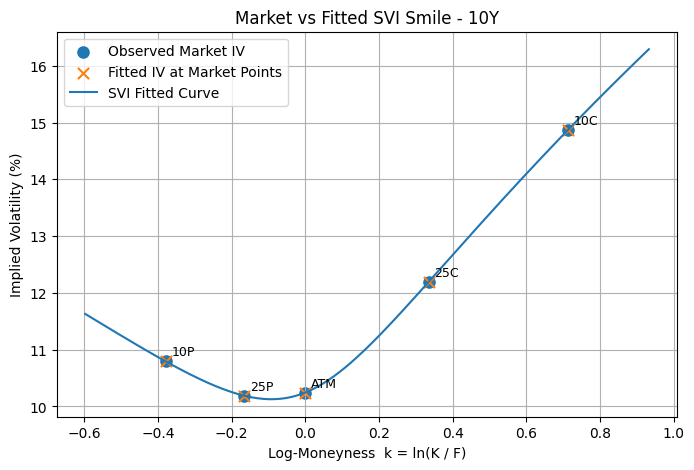

[Tenor: 15Y]


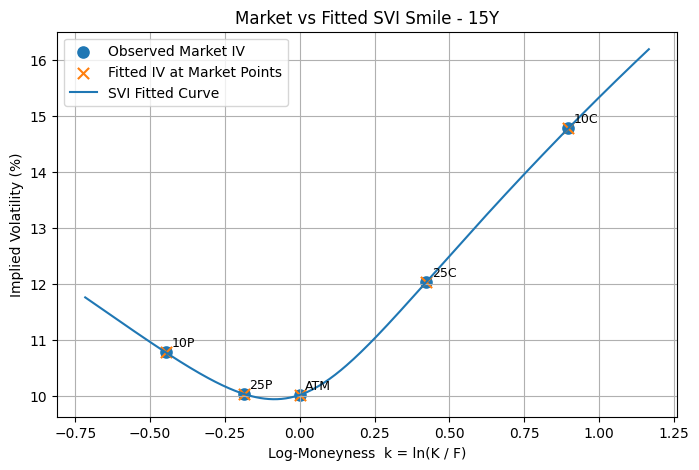

[Tenor: 20Y]


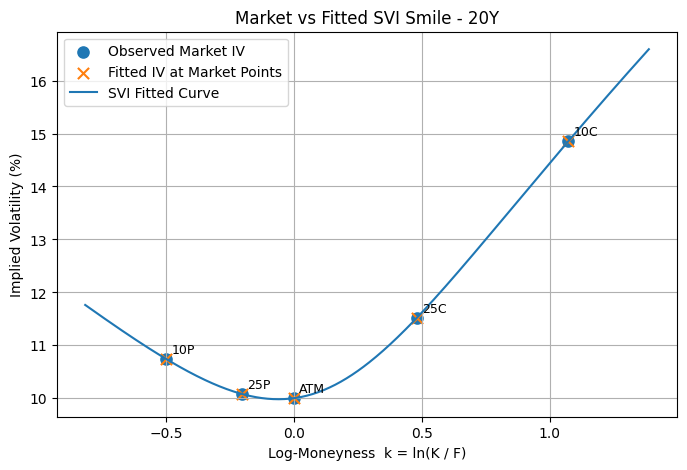

[Tenor: 25Y]


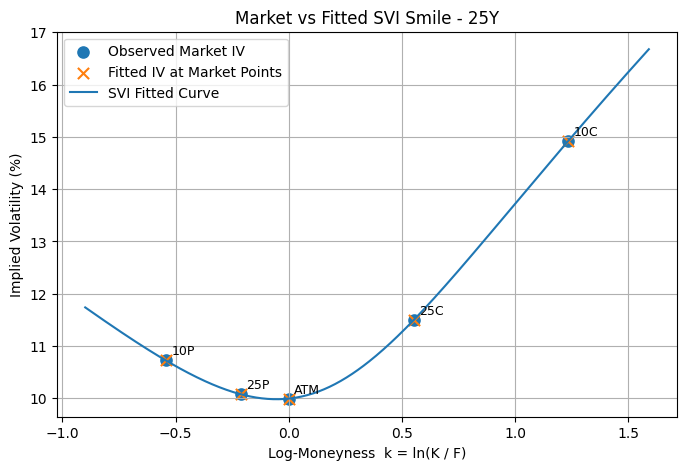

[Tenor: 30Y]


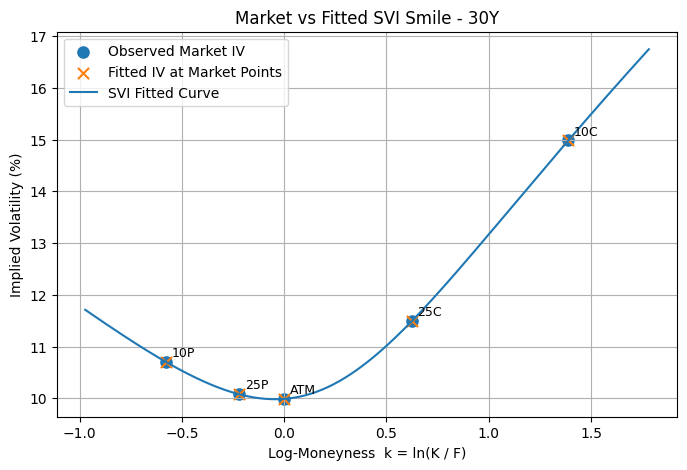

In [7]:
# =========================================================
# 5) 전체 테너별 스마일 시각화용 함수
# =========================================================
def plot_all_tenor_smiles(svi_input: pd.DataFrame,
                          svi_params: pd.DataFrame,
                          print_table: bool = False):
    """
    모든 테너(exp)에 대해
    1) 시장 IV vs fitted IV 비교표(optional)
    2) 스마일 플롯
    을 순차적으로 출력
    """

    if svi_params.empty:
        print("svi_params가 비어 있습니다. 먼저 피팅 결과를 확인하세요.")
        return

    exp_list = svi_params["Exp"].tolist()

    for exp in exp_list:
        print("=" * 80)
        print(f"[Tenor: {exp}]")

        comp = make_market_vs_fitted_table(exp, svi_input, svi_params)

        if comp is None or comp.empty:
            print(f"[SKIP] {exp}: usable point or fitted params not found.")
            continue

        if print_table:
            print(comp)

        plot_market_vs_fitted_slice_k(exp, svi_input, svi_params)


# =========================================================
# 6) 실행
# =========================================================
svi_input = build_svi_input(raw, valuation_date=VALUATION_DATE, spot=SPOT)
svi_params = fit_all_svi_slices(svi_input, raw)

print("[SVI Parameters]")
print(svi_params)

# 모든 테너별 스마일 시각화
plot_all_tenor_smiles(
    svi_input=svi_input,
    svi_params=svi_params,
    print_table=False   # True로 바꾸면 각 테너별 비교표도 함께 출력
)

## 6. 전체 만기 SVI Smile Overlay 시각화

이 단계는 각 만기별로 따로 확인했던 SVI smile을 하나의 2차원 그래프 위에 겹쳐서 비교하는 과정입니다.  
`plot_all_smiles_overlay()` 함수는 모든 만기를 잔존만기 (T) 기준으로 정렬한 뒤, 각 만기의 SVI fitted curve를 같은 좌표평면에 표시합니다.  색상은 rainbow colormap을 사용하여 만기별 곡선을 구분한다.  

 동일한 moneyness 구간에서 만기가 달라질수록 변동성 수준과 smile 형태가 어떻게 달라지는지 한눈에 볼 수 있으며, `show_observed=True`로 설정하면 각 만기의 실제 시장 관측점도 함께 표시되므로, fitted curve가 시장 quote를 얼마나 잘 통과하는지 확인할 수 있습니다.  

다만 이것만으로 변동성 곡면을 만들었다고 보기는 어렵습니다. 변동성 곡면은 다음 과제를 참고해주세요.

In [8]:
# =========================================================
# 모든 테너 스마일을 하나의 그림에 겹쳐서 시각화
# - rainbow 색상 적용 버전
# =========================================================
def plot_all_smiles_overlay(svi_input: pd.DataFrame,
                            svi_params: pd.DataFrame,
                            show_observed: bool = True,
                            grid_points: int = 300,
                            pad_ratio: float = 0.15,
                            figsize=(10, 6)):
    """
    모든 테너의 SVI 스마일을 하나의 plot 위에 overlay해서 시각화
    rainbow colormap 적용
    """

    if svi_params.empty:
        print("svi_params가 비어 있습니다. 먼저 피팅 결과를 확인하세요.")
        return

    # T 기준으로 정렬
    exp_order = (
        svi_input.groupby("Exp", as_index=False)["T"]
        .first()
        .sort_values("T")["Exp"]
        .tolist()
    )

    n_exp = len(exp_order)

    # rainbow 색상 생성
    colors = plt.cm.rainbow(np.linspace(0, 1, n_exp))

    plt.figure(figsize=figsize)

    for i, exp in enumerate(exp_order):
        comp = make_market_vs_fitted_table(exp, svi_input, svi_params)

        if comp is None or comp.empty:
            print(f"[SKIP] {exp}: usable point or fitted params not found.")
            continue

        param_row = svi_params[svi_params["Exp"] == exp]
        if len(param_row) == 0:
            continue

        p = param_row.iloc[0]
        T = float(comp["T"].iloc[0])

        # 관측 k 범위
        k_obs = comp["log_moneyness"].values
        iv_obs = comp["observed_iv_pct"].values

        k_min = k_obs.min()
        k_max = k_obs.max()
        k_range = max(k_max - k_min, 1e-6)

        k_grid = np.linspace(
            k_min - pad_ratio * k_range,
            k_max + pad_ratio * k_range,
            grid_points
        )

        w_grid = raw_svi_total_variance(
            k_grid, p["a"], p["b"], p["rho"], p["m"], p["sigma"]
        )
        iv_grid = np.sqrt(np.maximum(w_grid, 0.0) / T) * 100.0

        # fitted curve
        plt.plot(
            k_grid,
            iv_grid,
            color=colors[i],
            linewidth=2,
            label=f"{exp}"
        )

        # observed market points
        if show_observed:
            plt.scatter(
                k_obs,
                iv_obs,
                color=colors[i],
                s=20,
                alpha=0.7
            )

    plt.xlabel("Log-Moneyness  k = ln(K / F)")
    plt.ylabel("Implied Volatility (%)")
    plt.title("Overlay of SVI Smiles Across All Tenors")
    plt.grid(True)
    plt.legend(title="Tenor", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [ ]:
# =========================================================
# 실행
# =========================================================
svi_input = build_svi_input(raw, valuation_date=VALUATION_DATE, spot=SPOT)
svi_params = fit_all_svi_slices(svi_input, raw)

print("[SVI Parameters]")
print(svi_params)

# 모든 테너를 한 그림에 overlay
plot_all_smiles_overlay(
    svi_input=svi_input,
    svi_params=svi_params,
    show_observed=True
)

## 7. Plotly 기반 3D SVI Smile Slice 시각화

이전에 만들었던 테너별 스마일을 3차원 공간에서 시각화하는 코드입니다.  
2차원 그래프는 모든 스마일을 한 평면에 겹쳐 보여주지만, 이 함수는 만기 (T)를 별도의 축으로 두어 테너별 스마일의 변화를 더 쉽게 볼 수 있습니다.  

여러 만기의 스마일을 함께 보면, 만기 방향으로 스마일이 어떻게 이동하고 변형되는지 확인할 수 있습니다.

In [9]:
import plotly.graph_objects as go
import plotly.express as px


def plot_svi_slices_3d_interactive(
    svi_input: pd.DataFrame,
    svi_params: pd.DataFrame,
    show_observed: bool = True,
    grid_points: int = 300,
    pad_ratio: float = 0.15,
    width: int = 1100,
    height: int = 800
):
    """
    Plotly 기반 회전 가능한 3D SVI smile slices

    Axes
    ----
    x : log-moneyness k = ln(K/F)
    y : maturity T
    z : implied volatility (%)
    """

    if svi_params.empty:
        print("svi_params가 비어 있습니다. 먼저 피팅 결과를 확인하세요.")
        return

    # T 기준으로 테너 정렬
    exp_order = (
        svi_input.groupby("Exp", as_index=False)["T"]
        .first()
        .sort_values("T")["Exp"]
        .tolist()
    )

    n_exp = len(exp_order)

    # rainbow 계열 색상
    colors = px.colors.sample_colorscale("Rainbow", np.linspace(0, 1, n_exp))

    fig = go.Figure()

    for i, exp in enumerate(exp_order):
        comp = make_market_vs_fitted_table(exp, svi_input, svi_params)

        if comp is None or comp.empty:
            print(f"[SKIP] {exp}: usable point or fitted params not found.")
            continue

        param_row = svi_params[svi_params["Exp"] == exp]
        if len(param_row) == 0:
            print(f"[SKIP] {exp}: parameter row not found.")
            continue

        p = param_row.iloc[0]
        T = float(comp["T"].iloc[0])

        # observed market points
        k_obs = comp["log_moneyness"].values.astype(float)
        iv_obs = comp["observed_iv_pct"].values.astype(float)

        k_min = k_obs.min()
        k_max = k_obs.max()
        k_range = max(k_max - k_min, 1e-6)

        k_grid = np.linspace(
            k_min - pad_ratio * k_range,
            k_max + pad_ratio * k_range,
            grid_points
        )

        w_grid = raw_svi_total_variance(
            k_grid, p["a"], p["b"], p["rho"], p["m"], p["sigma"]
        )
        iv_grid = np.sqrt(np.maximum(w_grid, 0.0) / T) * 100.0
        T_grid = np.full_like(k_grid, T, dtype=float)

        # fitted slice line
        fig.add_trace(
            go.Scatter3d(
                x=k_grid,
                y=T_grid,
                z=iv_grid,
                mode="lines",
                name=exp,
                line=dict(color=colors[i], width=6),
                hovertemplate=(
                    f"Tenor: {exp}<br>"
                    "k: %{x:.4f}<br>"
                    "T: %{y:.4f}<br>"
                    "Fitted IV: %{z:.4f}%<extra></extra>"
                )
            )
        )

        # observed market points
        if show_observed:
            T_obs = np.full_like(k_obs, T, dtype=float)

            fig.add_trace(
                go.Scatter3d(
                    x=k_obs,
                    y=T_obs,
                    z=iv_obs,
                    mode="markers",
                    name=f"{exp} observed",
                    marker=dict(
                        size=4,
                        color=colors[i],
                        opacity=0.9
                    ),
                    showlegend=False,
                    hovertemplate=(
                        f"Tenor: {exp}<br>"
                        "k: %{x:.4f}<br>"
                        "T: %{y:.4f}<br>"
                        "Observed IV: %{z:.4f}%<extra></extra>"
                    )
                )
            )

    fig.update_layout(
        title="Interactive 3D SVI Smile Slices Across Tenors",
        width=width,
        height=height,
        scene=dict(
            xaxis_title="Log-Moneyness  k = ln(K / F)",
            yaxis_title="Maturity T",
            zaxis_title="Implied Volatility (%)",
            bgcolor="white",
            xaxis=dict(showbackground=True, backgroundcolor="rgb(245,245,245)"),
            yaxis=dict(showbackground=True, backgroundcolor="rgb(245,245,245)"),
            zaxis=dict(showbackground=True, backgroundcolor="rgb(245,245,245)")
        ),
        legend=dict(
            title="Tenor",
            x=1.02,
            y=1.0
        ),
        margin=dict(l=0, r=0, b=0, t=50)
    )

    fig.show()

In [10]:
# =========================================================
# 실행
# =========================================================
svi_input = build_svi_input(raw, valuation_date=VALUATION_DATE, spot=SPOT)
svi_params = fit_all_svi_slices(svi_input, raw)

print("[SVI Parameters]")
print(svi_params)

plot_svi_slices_3d_interactive(
    svi_input=svi_input,
    svi_params=svi_params,
    show_observed=True,
    grid_points=300,
    pad_ratio=0.15,
    width=1200,
    height=850
)

[SVI Parameters]
               a         b       rho         m     sigma  rmse_total_variance  \
0   2.083183e-05  0.001009  0.096608  0.000341  0.005773         5.892209e-17   
1   1.298106e-04  0.001998  0.256447 -0.001489  0.010144         5.982792e-19   
2   2.525747e-04  0.003077  0.329962 -0.001013  0.014661         5.746852e-07   
3   3.787993e-04  0.003063  0.442328 -0.003515  0.014995         5.149275e-07   
4   5.506376e-04  0.004972  0.366472 -0.002072  0.021065         6.706037e-07   
5   1.083038e-03  0.007769  0.423692 -0.001472  0.029712         1.346245e-06   
6   1.319181e-03  0.012395  0.336614 -0.004385  0.048881         1.918165e-06   
7   1.749899e-03  0.014951  0.378787 -0.004102  0.059145         3.174766e-06   
8   1.945367e-03  0.019093  0.380164 -0.003494  0.073195         7.005224e-06   
9   1.270144e-03  0.026230  0.308691 -0.005140  0.102968         9.349415e-06   
10  8.720293e-04  0.038066  0.293391 -0.007461  0.137111         2.687332e-05   
11  1.00000

결과 해석

---

**만기별 스마일 형태 변화**: 만기가 달라짐에 따라
스마일 곡선(변동성의 비대칭성 및 왜도)이 어떻게 변하는지 한눈에 볼 수 있습니다. 예를 들어, 단기 만기에서는 스마일이 더 가파르거나 비대칭적일 수 있고, 장기 만기에서는 더 완만해지거나 대칭에 가까워질 수 있습니다.

**변동성 곡면의 연속성**: SVI 모델이 만기 축을 따라 변동성 곡면을 얼마나 부드럽고 일관되게 연결하는지 확인할 수 있습니다.

**피팅 품질**: 피팅된 SVI 곡선이 시장 관측점들을 얼마나 잘 통과하는지, 특히 ATM과 OTM 옵션 영역에서 오차가 어떻게 나타나는지 시각적으로 평가할 수 있습니다.